# Traffic Sign Recognition with YOLO and CNN

YOLO11n finds signs in a road image. Our CNN then names each cropped sign.

**Run All** shows the results from our saved files and tries one road image. It does not retrain the models. To repeat training, change the switches in the first code cell. Training on a CPU takes a long time.

## 1. Find the project

In VS Code, open the project folder and select its Python environment. In Colab, put the whole project folder in `MyDrive/DeepLearning_Poject` and set `USE_DRIVE = True`. The GitHub repository is private, so cloning it requires access.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

USE_DRIVE = False
GITHUB_URL = ""  # Optional in Colab, if your account can access the private repository
RUN_TRAINING = False
RUN_EXPERIMENTS = False
RUN_LIVE_PREDICTION = True
LAUNCH_DEMO = False

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

candidates = [Path.cwd(), *Path.cwd().parents,
              Path('/content/drive/MyDrive/DeepLearning_Poject'),
              Path('/content/DeepLearning_Poject')]
PROJECT_ROOT = next((p for p in candidates if (p / 'requirements.txt').is_file()
                     and (p / 'traffic_signs').is_dir()), None)
if PROJECT_ROOT is None and GITHUB_URL:
    PROJECT_ROOT = Path('/content/DeepLearning_Poject')
    subprocess.run(['git', 'clone', GITHUB_URL, str(PROJECT_ROOT)], check=True)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the project folder in VS Code, or set USE_DRIVE=True in Colab.')

PROJECT_ROOT = PROJECT_ROOT.resolve()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
print('Project folder:', PROJECT_ROOT.name)
print('Training:', RUN_TRAINING, '| Experiments:', RUN_EXPERIMENTS)

Project folder: DeepLearning_Poject
Training: False | Experiments: False


## 2. Load the tools we need

Install `requirements.txt` once in your Python environment. The cells below read saved CSV, JSON, and image files. If a file is missing, the notebook says so and continues.

In [2]:
import json
import pandas as pd
from IPython.display import Image, display

pd.options.display.precision = 4

def show_json(path):
    if path.is_file():
        return json.loads(path.read_text(encoding='utf-8'))
    print('Missing:', path.relative_to(PROJECT_ROOT))
    return None

def show_table(path, columns=None):
    if not path.is_file():
        print('Missing:', path.relative_to(PROJECT_ROOT))
        return
    table = pd.read_csv(path)
    display(table[columns] if columns else table)

def show_image(path, width=700):
    if path.is_file():
        display(Image(filename=str(path), width=width))
    else:
        print('Missing:', path.relative_to(PROJECT_ROOT))

try:
    import torch
    print('PyTorch:', torch.__version__, '| GPU available:', torch.cuda.is_available())
except ImportError:
    print('PyTorch is missing. Install requirements.txt before training or live prediction.')

PyTorch: 2.14.1+cpu | GPU available: False


## 3. Prepare the datasets

GTSRB is for the 43-class CNN. GTSDB is for YOLO detection. To prepare data again, place the official GTSDB files in `data/raw/gtsdb/FullIJCNN2013/` and set `RUN_TRAINING = True`.

In [3]:
raw = PROJECT_ROOT / 'data' / 'raw'
processed = PROJECT_ROOT / 'data' / 'processed'
manifest = processed / 'gtsrb_manifest.csv'
data_yaml = processed / 'gtsdb_yolo' / 'gtsdb.yaml'

if RUN_TRAINING:
    gtsdb_root = raw / 'gtsdb' / 'FullIJCNN2013'
    if not (gtsdb_root / 'gt.txt').is_file():
        raise FileNotFoundError(f'Put gt.txt and the GTSDB images in {gtsdb_root}')
    from traffic_signs.common import set_seed
    from traffic_signs.data import prepare_gtsrb, prepare_gtsdb, verify_label_compatibility
    set_seed(42)
    prepare_gtsrb(raw / 'gtsrb', processed, seed=42)
    prepare_gtsdb(gtsdb_root, processed / 'gtsdb_yolo', seed=42)
    verify_label_compatibility(manifest, processed / 'gtsdb_yolo' / 'gtsdb_annotations.csv', processed)
else:
    print('Using saved dataset summaries when available.')

Using saved dataset summaries when available.


In [4]:
gtsrb = show_json(processed / 'gtsrb_summary.json')
gtsdb = show_json(processed / 'gtsdb_yolo' / 'gtsdb_summary.json')
if gtsrb and gtsdb:
    display(pd.DataFrame({'GTSRB images': gtsrb['split_counts'],
                          'GTSDB road images': gtsdb['image_counts']}))
    print('Annotated GTSDB signs:', gtsdb['annotated_instances'])
    print('GTSDB class IDs checked:', len(gtsdb['represented_class_ids']), 'of 43')
    print('Train/validation track overlap:', gtsrb['train_val_group_overlap'])

,GTSRB images,GTSDB road images
train,20820,510
test,12630,300
val,5820,90


Annotated GTSDB signs: 1213
GTSDB class IDs checked: 43 of 43
Train/validation track overlap: 0


## 4. Models and training settings

We trained a custom CNN for sign names and fine-tuned YOLO11n to find signs. These settings come from our saved training files.

In [5]:
architecture = show_json(PROJECT_ROOT / 'outputs' / 'architecture_summary.json')
if architecture:
    display(pd.DataFrame([
        {'model': 'Custom CNN', 'classes': architecture['cnn']['classes'],
         'parameters': architecture['cnn']['parameters']},
        {'model': 'YOLO11n detector', 'classes': len(architecture['yolo']['classes']),
         'parameters': architecture['yolo']['parameters']}
    ]))

model_base = PROJECT_ROOT / 'outputs' / ('notebook_runs' if RUN_TRAINING else '')
cnn_out = model_base / 'cnn'
yolo_out = model_base / 'yolo'
cnn_checkpoint = cnn_out / 'best.pt'
yolo_checkpoint = yolo_out / 'train' / 'weights' / 'best.pt'

,model,classes,parameters
0,Custom CNN,43,430283
1,YOLO11n detector,1,2604883


## 5. CNN training and test results

Our main CNN run used 12 epochs, batch size 128, and 64 × 64 images. The test results below are from the official GTSRB test split.

,epochs_run,best_epoch,batch,image_size,learning_rate,best_val_accuracy,device
0,12,11,128,64,0.001,0.9674,cpu


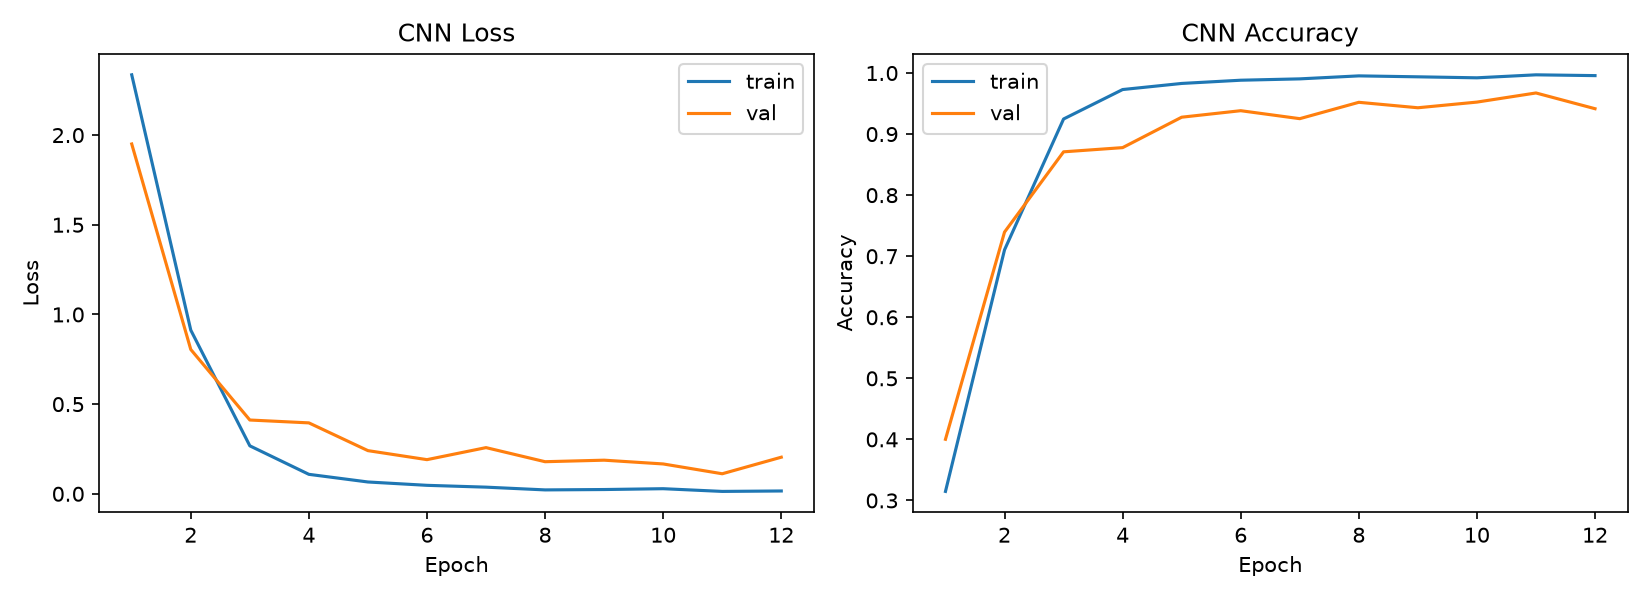

In [6]:
if RUN_TRAINING:
    from traffic_signs.cnn import train_cnn
    train_cnn(manifest, cnn_out, epochs=12, batch=128, size=64,
              lr=0.001, augment=True, seed=42, workers=0, patience=12)

cnn_train = show_json(cnn_out / 'train_summary.json')
if cnn_train:
    display(pd.DataFrame([cnn_train])[['epochs_run', 'best_epoch', 'batch',
                                       'image_size', 'learning_rate', 'best_val_accuracy', 'device']])
show_image(cnn_out / 'training_curves.png', width=650)

,split,samples,accuracy,precision_macro,recall_macro,f1_macro
0,test,12630,0.9599,0.9378,0.9305,0.9303


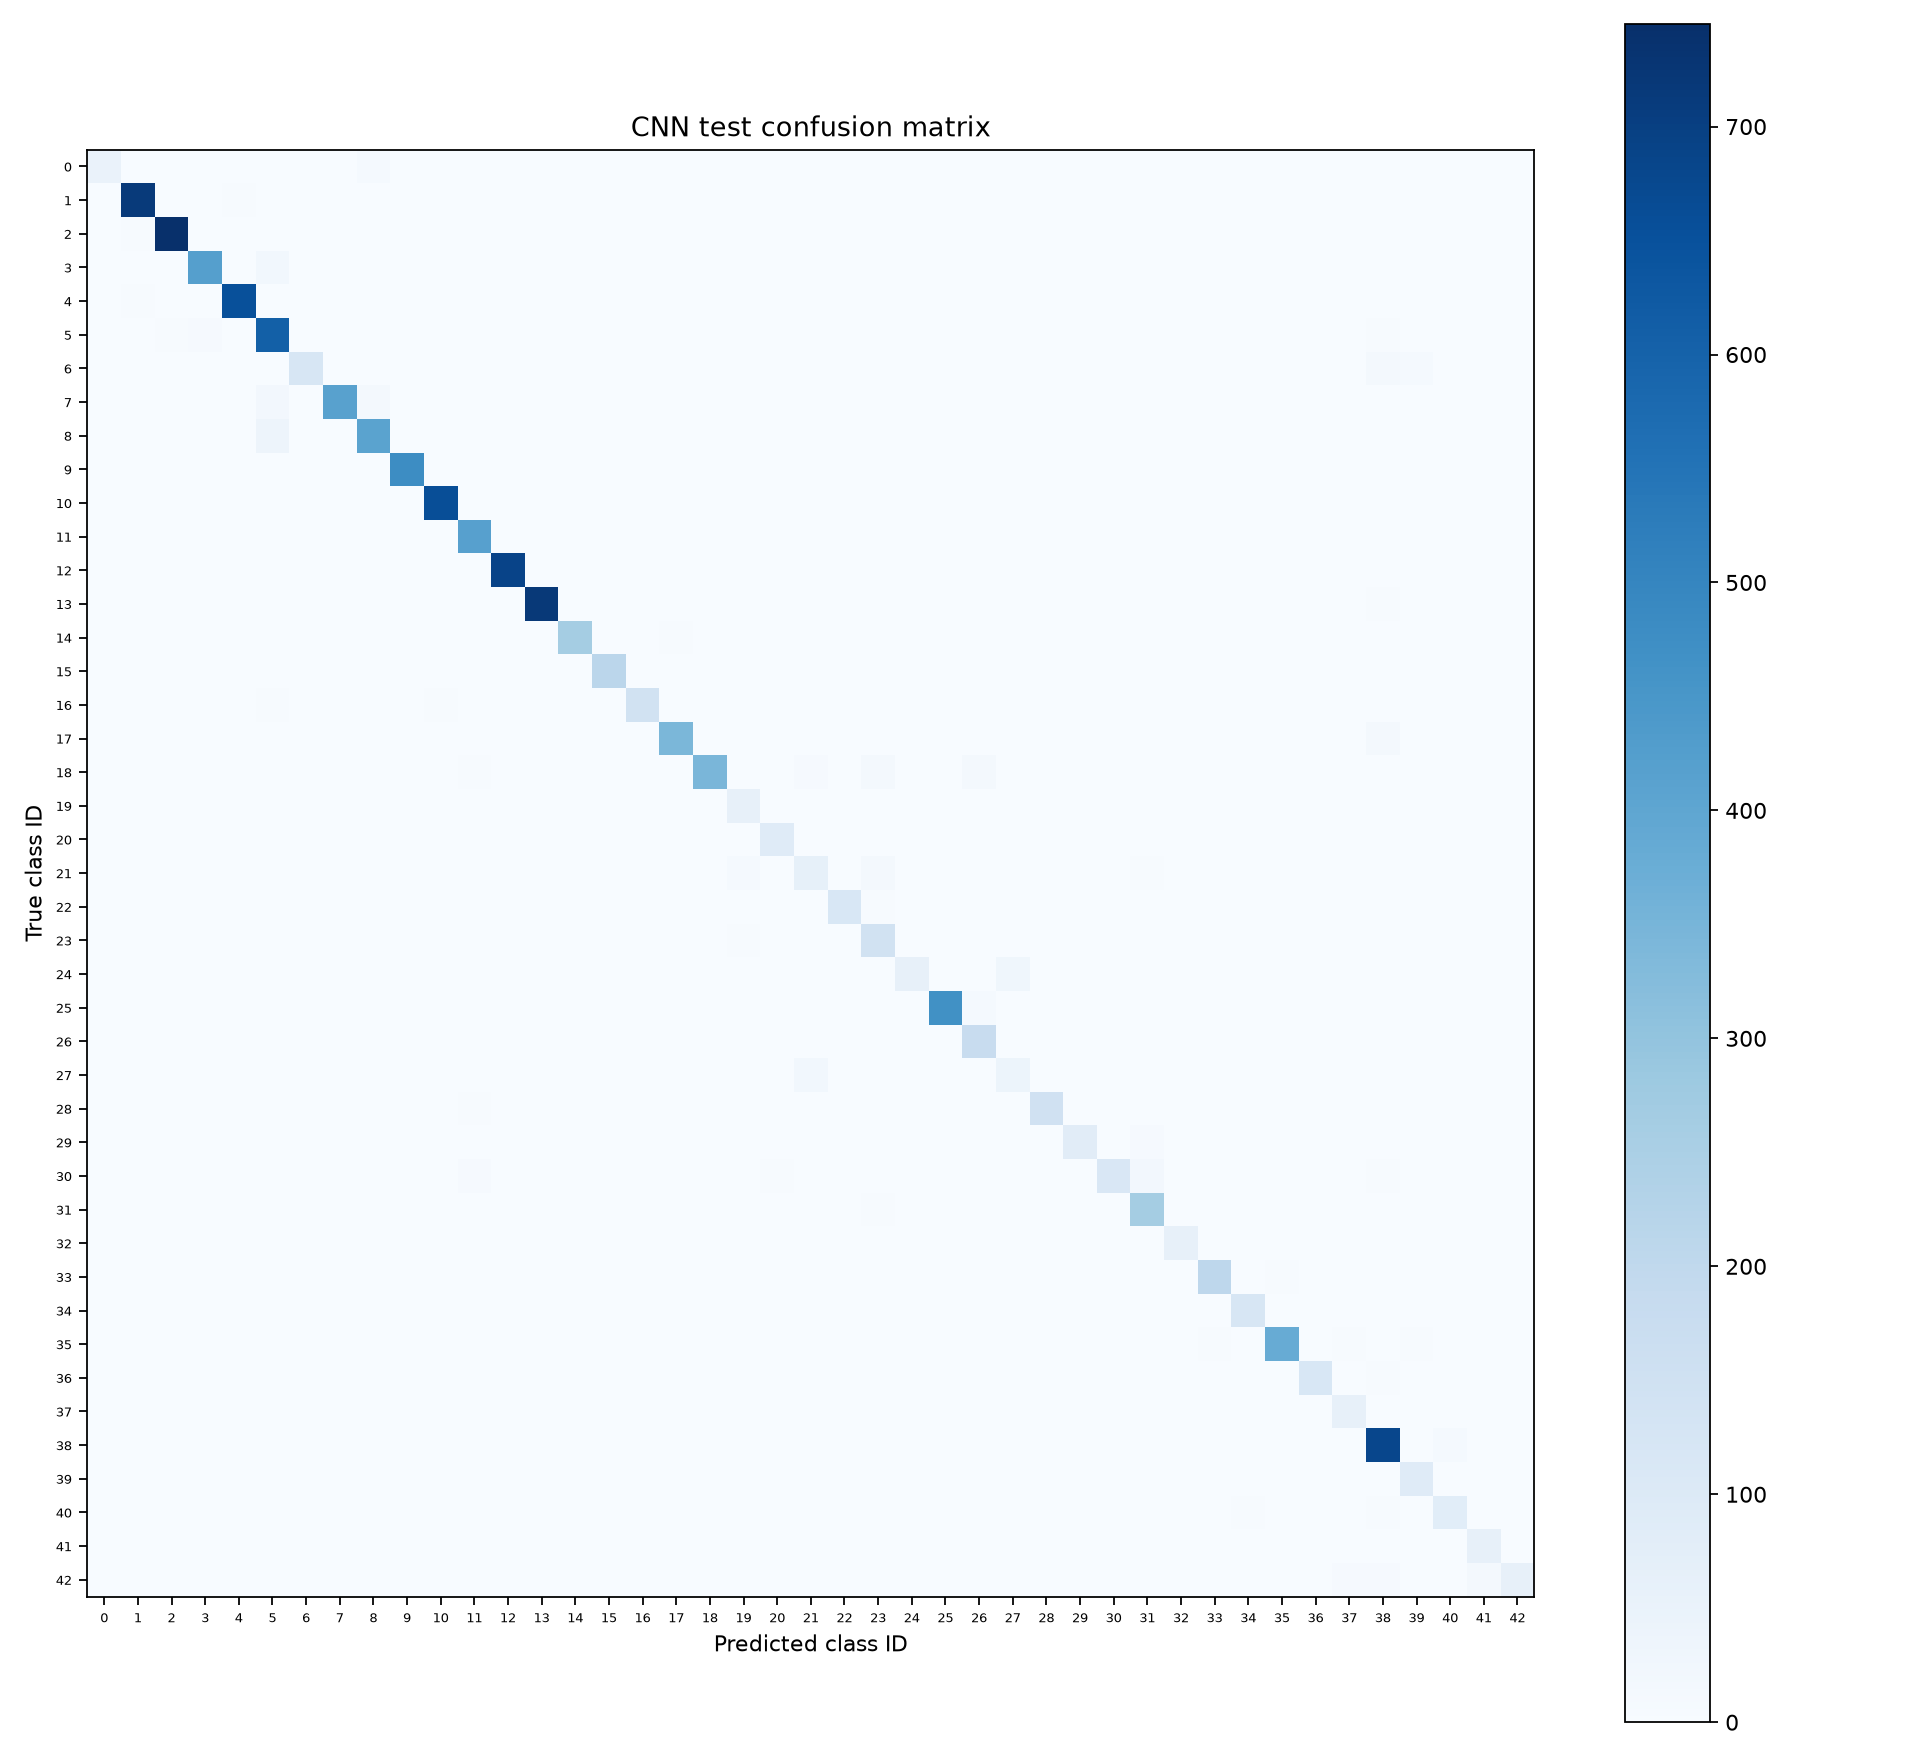

In [7]:
if RUN_TRAINING and cnn_checkpoint.is_file():
    from traffic_signs.cnn import evaluate_cnn
    evaluate_cnn(manifest, cnn_checkpoint, cnn_out / 'evaluation',
                 split='test', workers=0)

show_table(cnn_out / 'evaluation' / 'cnn_test_metrics.csv')
show_image(cnn_out / 'evaluation' / 'cnn_test_confusion.png', width=620)

## 6. YOLO training and test results

The main YOLO11n run used 10 epochs, 512-pixel images, and batch size 4. It learns one detection class: `traffic_sign`.

,epochs_requested,image_size,batch,learning_rate,seed
0,10,512,4,0.01,42


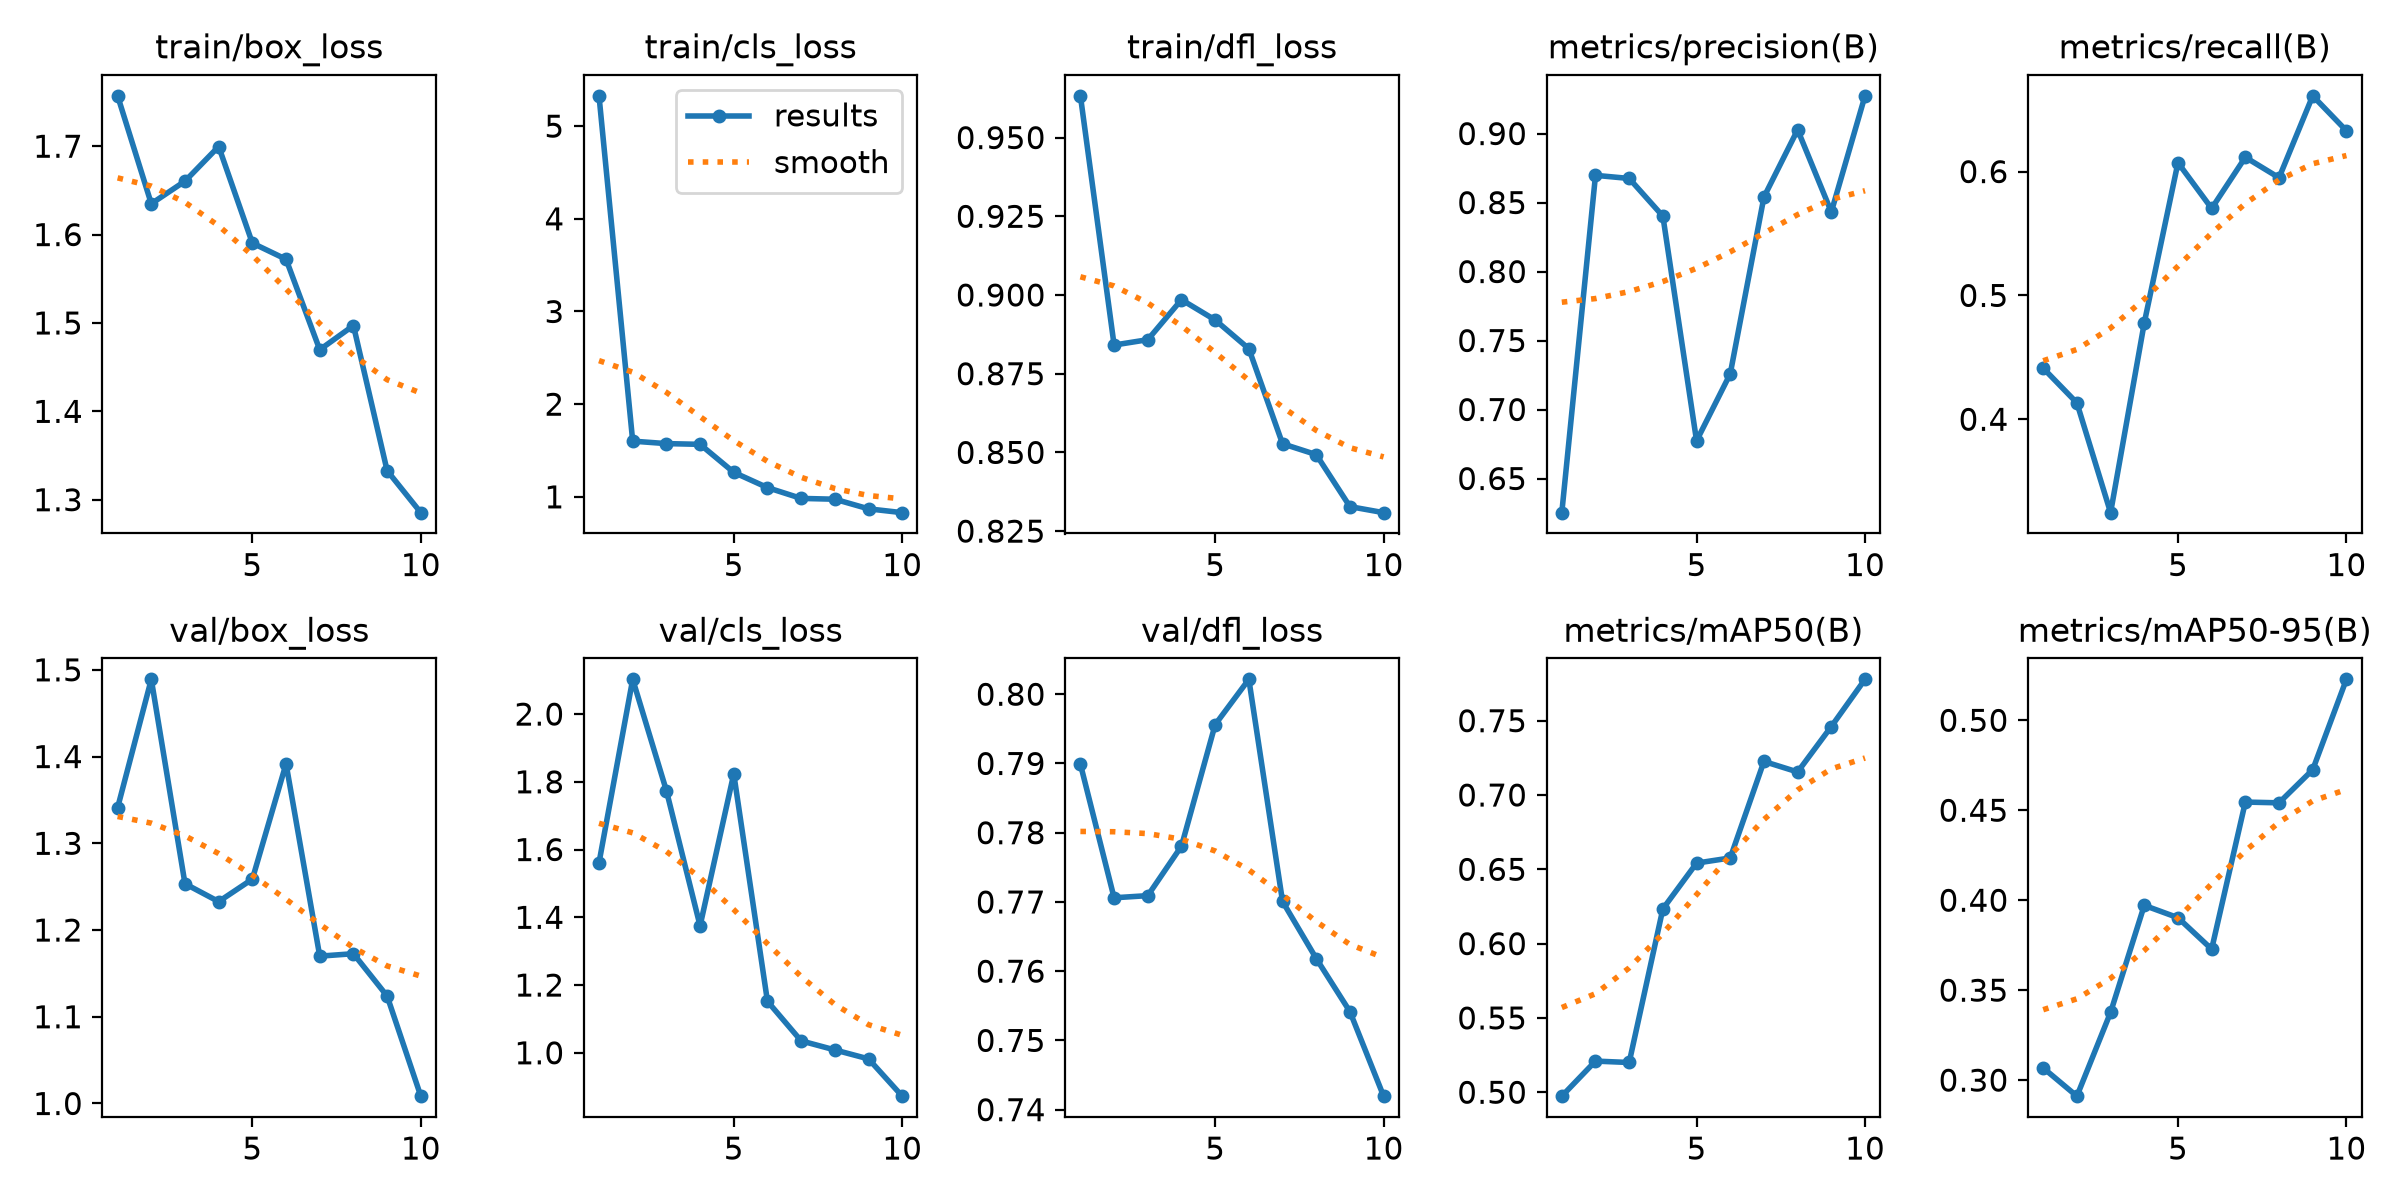

In [8]:
if RUN_TRAINING:
    from traffic_signs.yolo import train_yolo
    train_yolo(data_yaml, yolo_out, model_name='yolo11n.pt', epochs=10,
               image_size=512, batch=4, lr=0.01, seed=42, patience=10)

yolo_train = show_json(yolo_out / 'train_summary.json')
if yolo_train:
    display(pd.DataFrame([yolo_train])[['epochs_requested', 'image_size',
                                        'batch', 'learning_rate', 'seed']])
show_image(yolo_out / 'train' / 'results.png', width=700)

In [9]:
if RUN_TRAINING and yolo_checkpoint.is_file():
    from traffic_signs.yolo import evaluate_yolo
    evaluate_yolo(data_yaml, yolo_checkpoint, yolo_out / 'evaluation',
                  split='test', image_size=512, batch=4)

show_table(yolo_out / 'evaluation' / 'yolo_test_metrics.csv',
           ['precision', 'recall', 'map50', 'map50_95',
            'mean_inference_ms_per_image', 'image_size'])

,precision,recall,map50,map50_95,mean_inference_ms_per_image,image_size
0,0.8999,0.7701,0.8571,0.592,17.1275,512


## 7. YOLO + CNN together

YOLO finds each box. We crop it and let the CNN predict the sign name. A match counts only when the box overlaps the real sign and the name is correct.

In [10]:
integrated_out = model_base / 'integrated'
if RUN_TRAINING and cnn_checkpoint.is_file() and yolo_checkpoint.is_file():
    from traffic_signs.inference import TrafficSignSystem, evaluate_integrated
    system = TrafficSignSystem(yolo_checkpoint, cnn_checkpoint, image_size=512)
    evaluate_integrated(system, processed / 'gtsdb_yolo' / 'gtsdb_annotations.csv',
                        integrated_out, split='test')

show_table(integrated_out / 'integrated_metrics.csv')

,split,images,ground_truth_signs,predictions,matched_detections,correctly_classified_matches,detection_recall_at_iou,classification_accuracy_on_matches,end_to_end_recall,end_to_end_precision,iou_threshold
0,test,300,361,390,328,308,0.9086,0.939,0.8532,0.7897,0.5


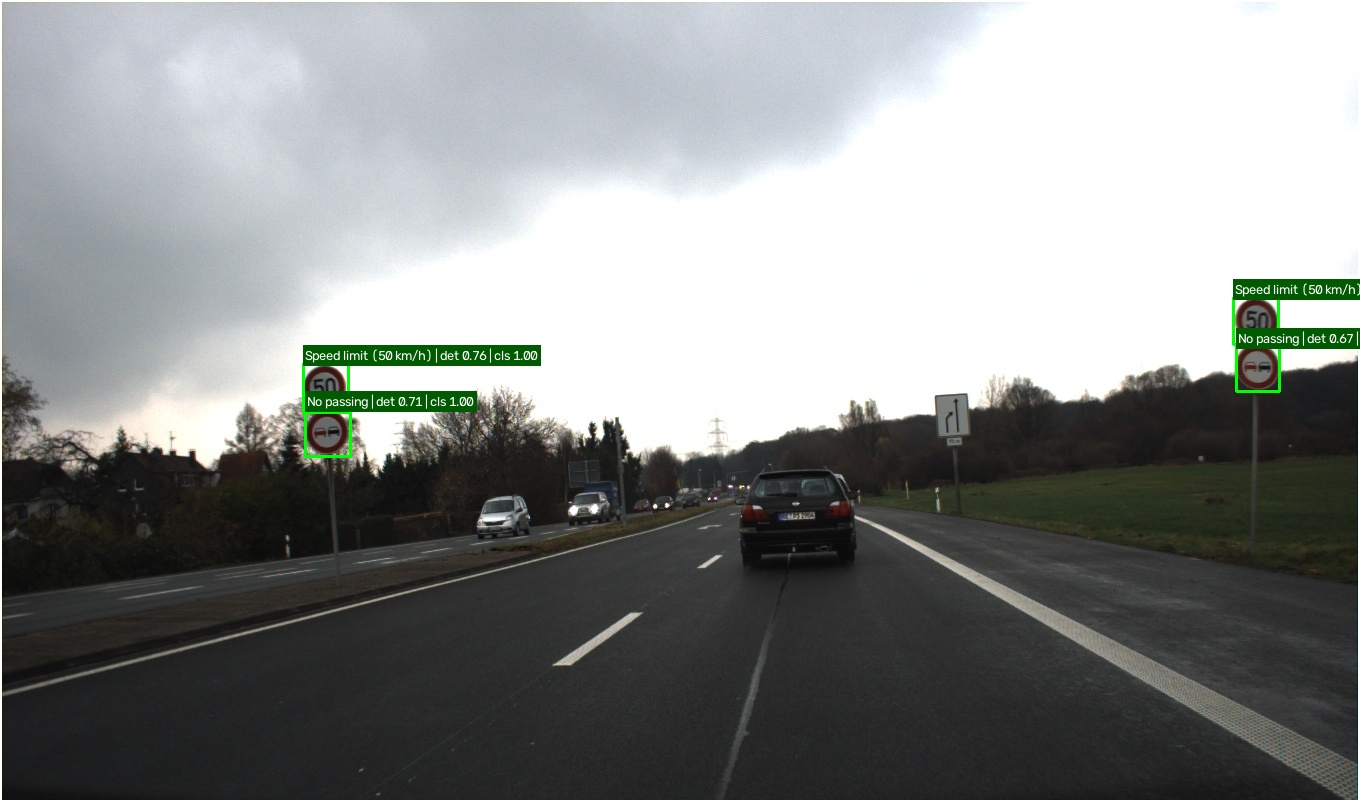

,class_name,detection_confidence,classification_confidence
0,Speed limit (50 km/h),0.764,0.999
1,Speed limit (50 km/h),0.763,0.999
2,No passing,0.713,1.000
3,No passing,0.675,1.000


In [11]:
sample = processed / 'gtsdb_yolo' / 'images' / 'test' / '00839.jpg'
if RUN_LIVE_PREDICTION and sample.is_file() and cnn_checkpoint.is_file() and yolo_checkpoint.is_file():
    import cv2
    from traffic_signs.inference import TrafficSignSystem
    system = TrafficSignSystem(yolo_checkpoint, cnn_checkpoint, image_size=512)
    annotated, signs = system.predict(cv2.imread(str(sample)))
    display(Image(data=cv2.imencode('.jpg', annotated)[1].tobytes(), width=850))
    if signs:
        display(pd.DataFrame(signs)[['class_name', 'detection_confidence',
                                     'classification_confidence']].round(3))
    else:
        print('No traffic signs were detected in this image.')
else:
    print('Live prediction needs the prepared sample image and both trained checkpoints.')
    show_image(PROJECT_ROOT / 'outputs' / 'predictions' / '00839.jpg', width=850)

## 8. Short experiments

These are separate validation runs. They are not the main CNN or YOLO test results. Set `RUN_EXPERIMENTS = True` to repeat them; this can take hours on a CPU.

,experiment,learning_rate,batch,image_size,best_val_accuracy
0,baseline,0.0010,128,64,0.8710
1,lower_lr,0.0003,128,64,0.7562
2,larger_image_smaller_batch,0.0010,64,80,0.8266


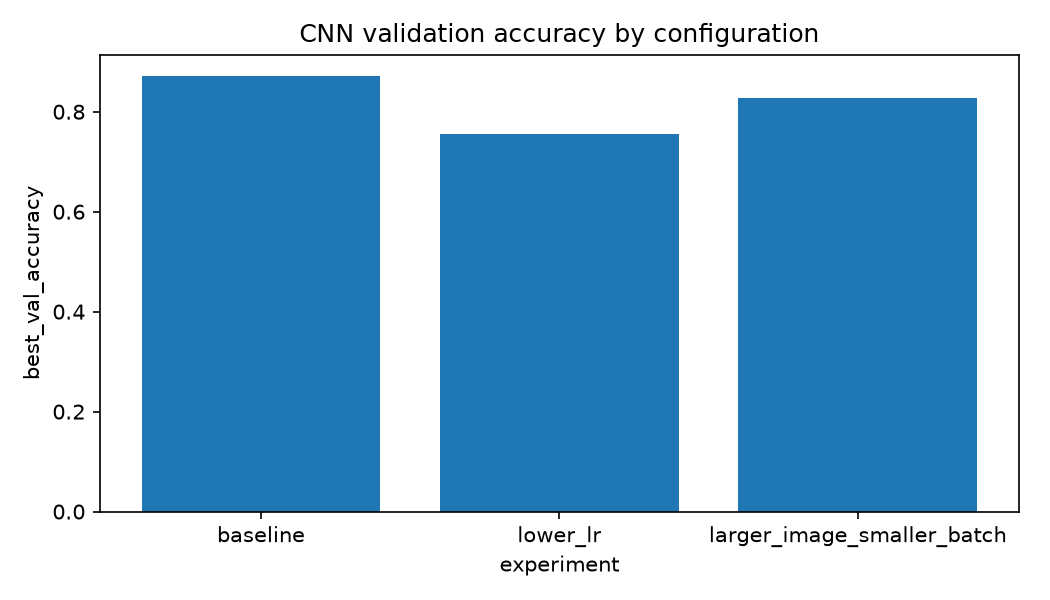

In [12]:
exp_out = PROJECT_ROOT / 'outputs' / ('notebook_runs/experiments' if RUN_EXPERIMENTS else 'experiments')
if RUN_EXPERIMENTS:
    from traffic_signs.experiments import tune_cnn
    tune_cnn(manifest, exp_out / 'cnn_tuning', epochs=3, seed=42, workers=0)

show_table(exp_out / 'cnn_tuning' / 'cnn_tuning.csv',
           ['experiment', 'learning_rate', 'batch', 'image_size', 'best_val_accuracy'])
show_image(exp_out / 'cnn_tuning' / 'cnn_tuning.png', width=600)

,experiment,learning_rate,batch,image_size,map50_95
0,baseline,0.010,16,640,0.5336
1,smaller_image,0.010,16,512,0.4068
2,smaller_batch_lr,0.005,8,640,0.5519


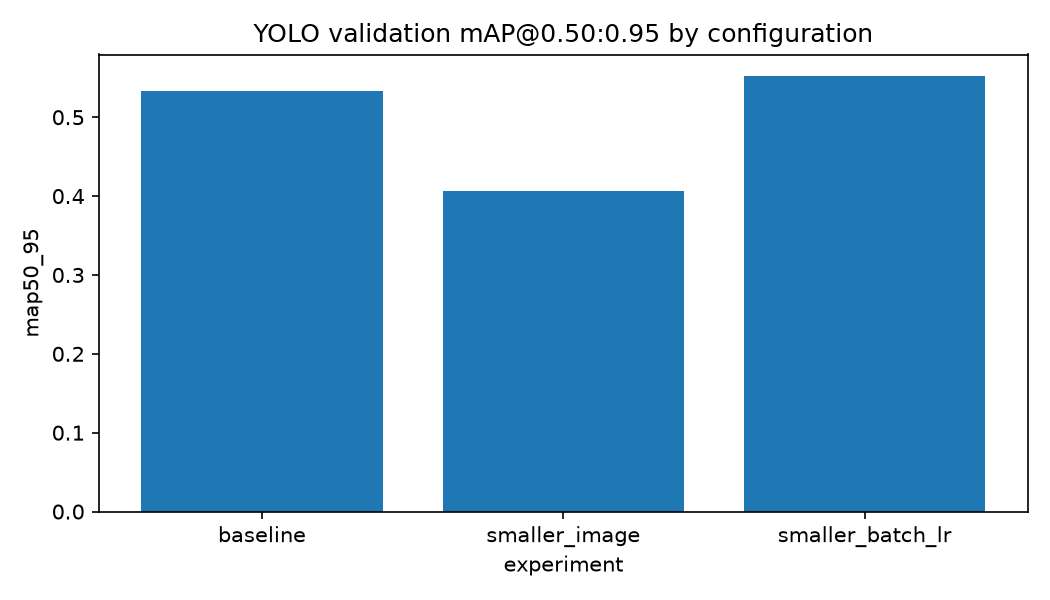

In [13]:
if RUN_EXPERIMENTS:
    from traffic_signs.experiments import tune_yolo
    tune_yolo(data_yaml, exp_out / 'yolo_tuning', epochs=3, seed=42)

show_table(exp_out / 'yolo_tuning' / 'yolo_tuning.csv',
           ['experiment', 'learning_rate', 'batch', 'image_size', 'map50_95'])
show_image(exp_out / 'yolo_tuning' / 'yolo_tuning.png', width=600)

,selected_features,val_accuracy,val_f1_macro
0,32,0.9256,0.8977
1,64,0.9543,0.9357
2,128,0.9577,0.9458
3,256,0.9598,0.9469


,best_feature_count,test_accuracy,test_f1_macro
0,256,0.9577,0.9202


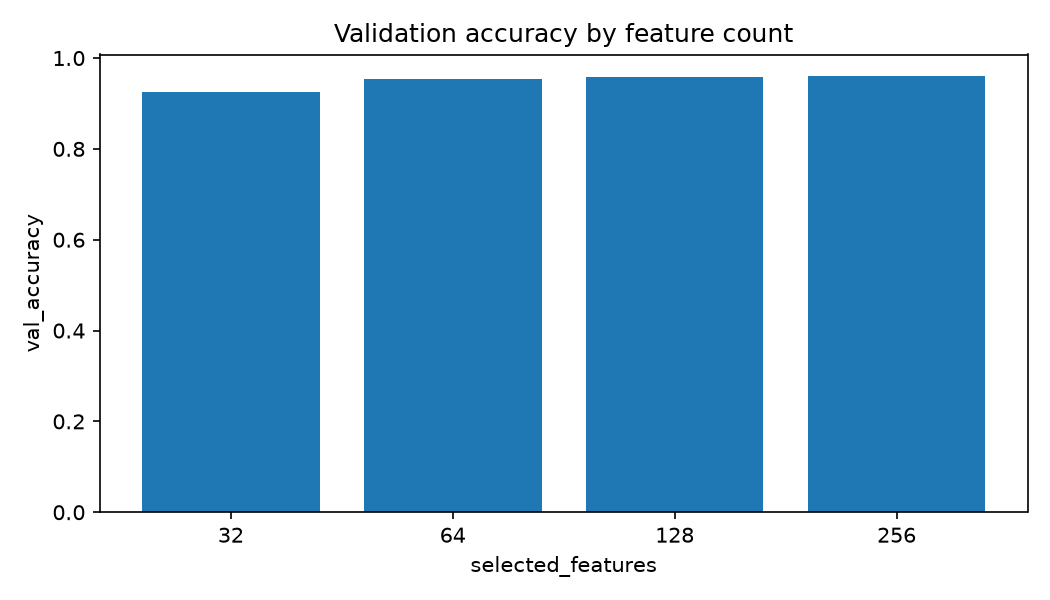

In [14]:
if RUN_EXPERIMENTS and cnn_checkpoint.is_file():
    from traffic_signs.experiments import feature_selection_experiment
    feature_selection_experiment(manifest, cnn_checkpoint,
                                 exp_out / 'features', workers=0, seed=42)

show_table(exp_out / 'features' / 'feature_selection_validation.csv')
feature_test = show_json(exp_out / 'features' / 'feature_selection_test.json')
if feature_test:
    display(pd.DataFrame([{k: feature_test[k] for k in
                           ('best_feature_count', 'test_accuracy', 'test_f1_macro')}]))
show_image(exp_out / 'features' / 'feature_selection.png', width=600)

,preprocessing,best_val_accuracy,epochs_run
0,resize_only,0.8055,3
1,augmented,0.8710,3


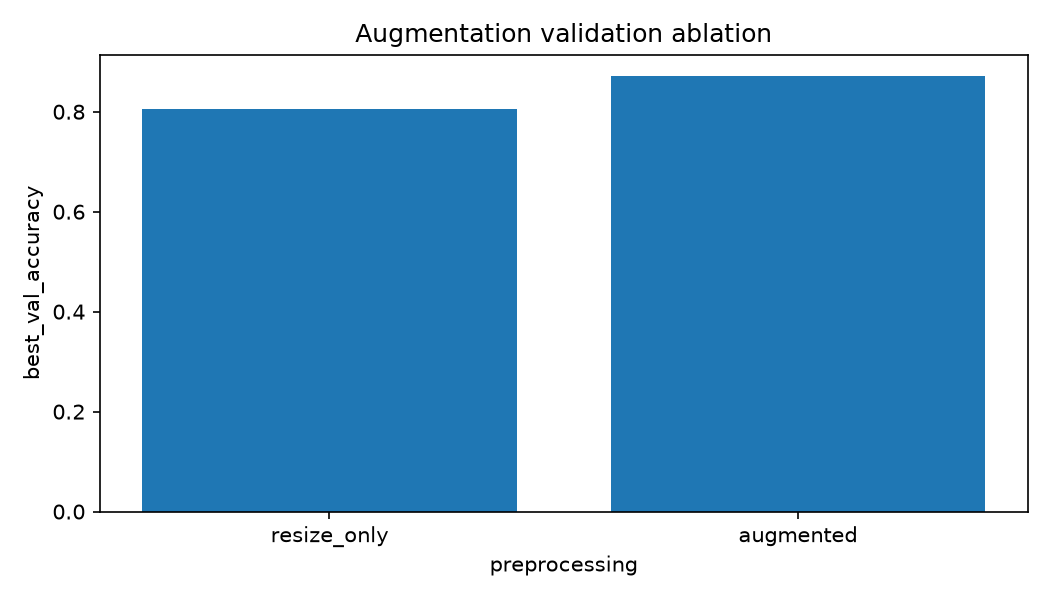

In [15]:
if RUN_EXPERIMENTS:
    from traffic_signs.experiments import augmentation_ablation
    augmentation_ablation(manifest, exp_out / 'augmentation',
                          seed=42, epochs=3, workers=0)

show_table(exp_out / 'augmentation' / 'augmentation_ablation.csv',
           ['preprocessing', 'best_val_accuracy', 'epochs_run'])
show_image(exp_out / 'augmentation' / 'augmentation_ablation.png', width=600)

## 9. Demo

Set `LAUNCH_DEMO = True` to upload your own road image. The demo keeps running until you stop the cell. You can also run `python -m scripts.demo` in the VS Code terminal.

In [16]:
if LAUNCH_DEMO:
    import cv2
    import gradio as gr
    from PIL import Image as PILImage
    from traffic_signs.inference import TrafficSignSystem

    system = TrafficSignSystem(yolo_checkpoint, cnn_checkpoint, image_size=512)
    def predict_for_demo(rgb):
        if rgb is None:
            return None, []
        marked, signs = system.predict(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
        rows = [[s['class_name'], round(s['detection_confidence'], 3),
                 round(s['classification_confidence'], 3)] for s in signs]
        return PILImage.fromarray(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB)), rows

    with gr.Blocks() as demo:
        gr.Markdown('# Traffic Sign Recognition')
        road = gr.Image(type='numpy', label='Road image')
        marked = gr.Image(label='Detected signs')
        names = gr.Dataframe(headers=['Sign', 'YOLO confidence', 'CNN confidence'])
        gr.Button('Detect and classify').click(predict_for_demo, road, [marked, names])
    demo.launch(share=False)
else:
    print('Demo skipped. Set LAUNCH_DEMO=True in Section 1 to open it.')

Demo skipped. Set LAUNCH_DEMO=True in Section 1 to open it.


## 10. Files and rerunning

Results shown above are read from `data/processed/` and `outputs/`. The GitHub repository contains the source code and this notebook; the large datasets and model checkpoints are stored separately. For a fresh run, install `requirements.txt`, add GTSDB under `data/raw/`, and set `RUN_TRAINING = True`.